In [1]:

import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

In [ ]:
df = pd.read_csv(r"C:\Users\ASUS\Downloads\nifty50_stock (6).csv")
# Remove 2nd and 3rd rows (Python uses zero-based indexing)
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
print(df.head(5))



        Price             Close              High               Low  \
0      Ticker             ^NSEI             ^NSEI             ^NSEI   
1  2007-09-18   4546.2001953125   4551.7998046875   4481.5498046875   
2  2007-09-19  4732.35009765625            4739.0           4550.25   
3  2007-09-20   4747.5498046875  4760.85009765625  4721.14990234375   
4  2007-09-21   4837.5498046875   4855.7001953125   4733.7001953125   

               Open Volume  
0             ^NSEI  ^NSEI  
1  4494.10009765625      0  
2           4550.25      0  
3  4734.85009765625      0  
4   4752.9501953125      0  


In [5]:
df.columns

Index(['Price', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object')

In [6]:
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked
print(df.head())


        Price             Close              High               Low  \
0  2007-09-18   4546.2001953125   4551.7998046875   4481.5498046875   
1  2007-09-19  4732.35009765625            4739.0           4550.25   
2  2007-09-20   4747.5498046875  4760.85009765625  4721.14990234375   
3  2007-09-21   4837.5498046875   4855.7001953125   4733.7001953125   
4  2007-09-24   4932.2001953125  4941.14990234375  4837.14990234375   

               Open Volume  
0  4494.10009765625      0  
1           4550.25      0  
2  4734.85009765625      0  
3   4752.9501953125      0  
4  4837.14990234375      0  


In [13]:
df.columns.values[0] = 'Date'
df.to_csv('nifty50.csv', index=False)


In [14]:
df.head()

,Date,Close,High,Low,Open,Volume
0,2007-09-18,4546.2001953125,4551.7998046875,4481.5498046875,4494.10009765625,0
1,2007-09-19,4732.35009765625,4739.0,4550.25,4550.25,0
2,2007-09-20,4747.5498046875,4760.85009765625,4721.14990234375,4734.85009765625,0
3,2007-09-21,4837.5498046875,4855.7001953125,4733.7001953125,4752.9501953125,0
4,2007-09-24,4932.2001953125,4941.14990234375,4837.14990234375,4837.14990234375,0


In [17]:
df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually


In [20]:
# Convert all columns (except Date) to numeric
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')

# Confirm that everything is now numeric
print(df.dtypes)


Date           datetime64[ns]
Open                  float64
High                  float64
Low                   float64
Close                 float64
Volume                  int64
Open_lag_1            float64
Close_lag_1           float64
High_lag_1            float64
Low_lag_1             float64
Open_lag_2            float64
Close_lag_2           float64
High_lag_2            float64
Low_lag_2             float64
Open_lag_3            float64
Close_lag_3           float64
High_lag_3            float64
Low_lag_3             float64
Open_lag_4            float64
Close_lag_4           float64
High_lag_4            float64
Low_lag_4             float64
Open_lag_5            float64
Close_lag_5           float64
High_lag_5            float64
Low_lag_5             float64
MA_5                  float64
STD_5                 float64
DayOfWeek               int32
Month                   int32
dtype: object


C:\Users\ASUS\AppData\Local\Temp\ipykernel_35276\3669918811.py:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 21780912.0000 - val_loss: 34562132.0000
Epoch 2/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 15158118.0000 - val_loss: 29851136.0000
Epoch 3/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8929825.0000 - val_loss: 6527913.5000
Epoch 4/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 6814397.0000 - val_loss: 12080049.0000
Epoch 5/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 4179247.0000 - val_loss: 4640376.0000
Epoch 6/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2083870.2500 - val_loss: 1314757.2500
Epoch 7/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 912899.5000 - val_loss: 259203.8438
Epoch 8/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 590035.7500 - val_loss: 224228.0000
Epoch 9/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 433589.0938 - val_loss: 269193.4062
Epoch 10/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 315547.1562 - val_loss: 229478.3750
Epoch 11/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

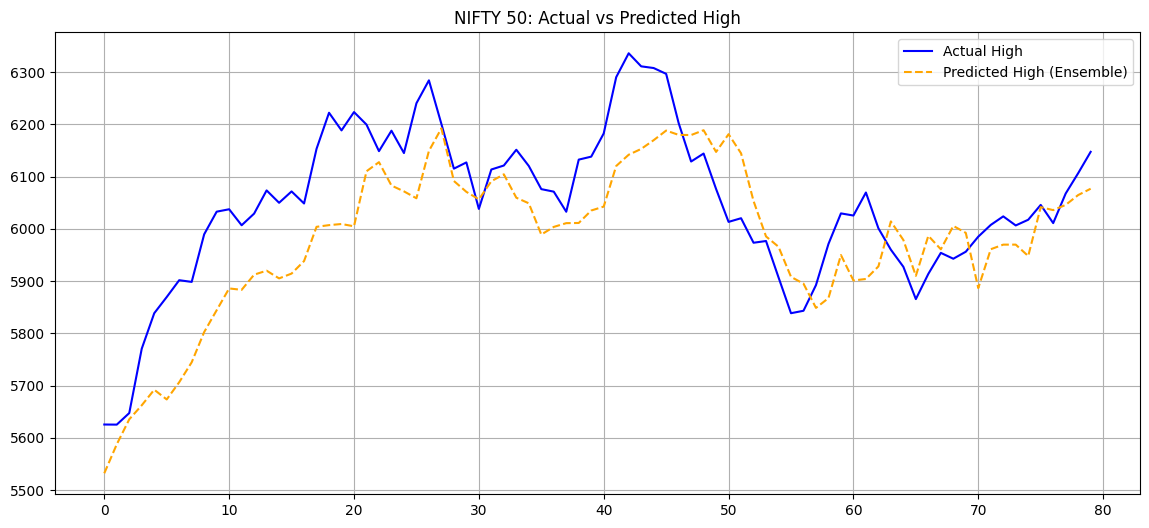

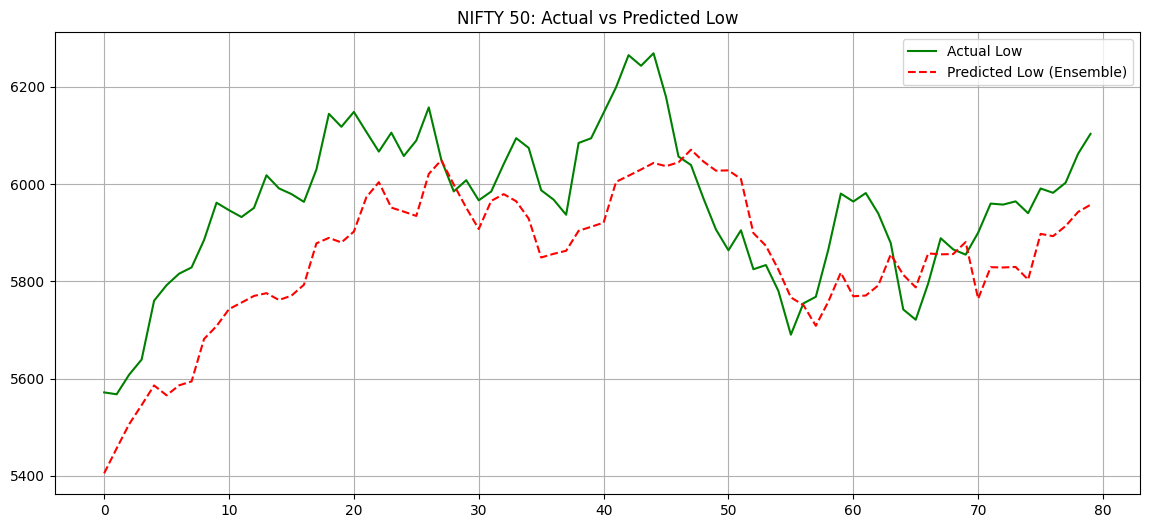

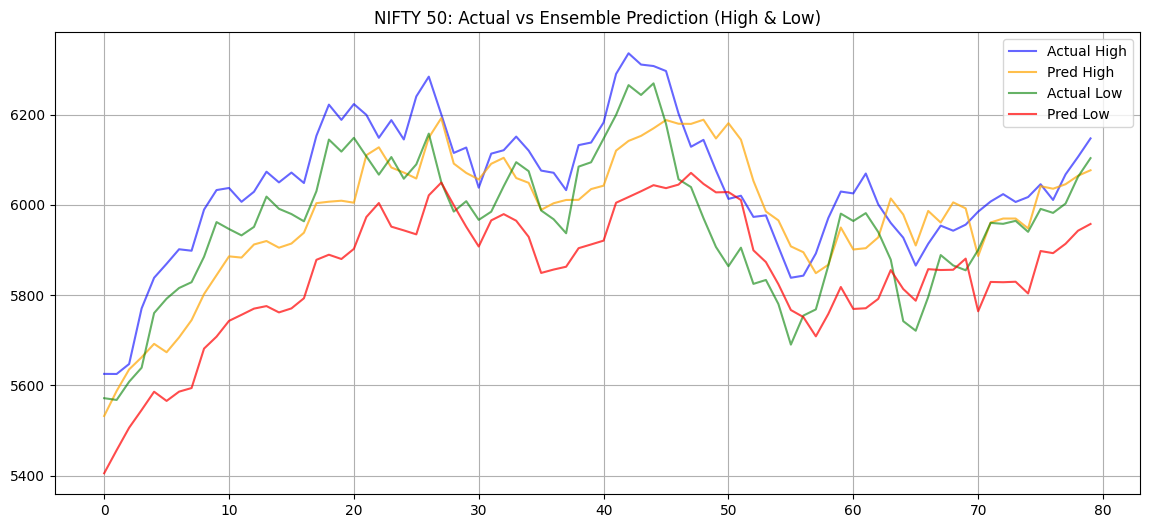

In [21]:
# ================================================================
# NIFTY 50 High–Low Forecasting: XGBoost + ConvLSTM + Ensemble
# ================================================================



# ----------------------------------------------------------
# STEP 1: LOAD AND PREPARE DATA
# ------------------------------------------------------------
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Create lag features
for lag in range(1, 6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Rolling mean and std
df['MA_5'] = df['Close'].rolling(window=5).mean()
df['STD_5'] = df['Close'].rolling(window=5).std()

# Date-time features
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

# Drop NaN
df = df.dropna().reset_index(drop=True)

# ------------------------------------------------------------
# STEP 2: DEFINE FEATURES & TARGETS
# ------------------------------------------------------------
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-Test Split (no shuffle, to preserve time order)
split_ratio = 0.9
split_idx = int(len(df) * split_ratio)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# STEP 3: XGBOOST MODELS (TABULAR)
# ------------------------------------------------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

pred_high_xgb = xgb_high.predict(X_test_scaled)
pred_low_xgb = xgb_low.predict(X_test_scaled)

# ------------------------------------------------------------
# STEP 4: ConvLSTM MODEL (SEQUENTIAL)
# ------------------------------------------------------------
def create_sequences(X, y_high, y_low, seq_len=5):
    X_seq, yh_seq, yl_seq = [], [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        yh_seq.append(y_high[i])
        yl_seq.append(y_low[i])
    return np.array(X_seq), np.array(yh_seq), np.array(yl_seq)

seq_len = 5
X_scaled_full = scaler.fit_transform(X)
X_seq, y_high_seq, y_low_seq = create_sequences(X_scaled_full, y_high.values, y_low.values, seq_len)

split_idx_seq = int(len(X_seq) * split_ratio)
X_train_seq, X_test_seq = X_seq[:split_idx_seq], X_seq[split_idx_seq:]
y_high_train_seq, y_high_test_seq = y_high_seq[:split_idx_seq], y_high_seq[split_idx_seq:]
y_low_train_seq, y_low_test_seq = y_low_seq[:split_idx_seq], y_low_seq[split_idx_seq:]

# Reshape for ConvLSTM: [samples, timesteps, rows, cols, features]
X_train_seq = X_train_seq.reshape((X_train_seq.shape[0], seq_len, 1, 1, X_train_seq.shape[2]))
X_test_seq = X_test_seq.reshape((X_test_seq.shape[0], seq_len, 1, 1, X_test_seq.shape[2]))

model = Sequential([
    ConvLSTM2D(32, (1,1), activation='relu', input_shape=(seq_len, 1, 1, X_train_seq.shape[-1]), return_sequences=True),
    Dropout(0.2),
    ConvLSTM2D(16, (1,1), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2)
])
model.compile(optimizer=Adam(0.001), loss='mse')

y_train_seq_combined = np.column_stack((y_high_train_seq, y_low_train_seq))
y_test_seq_combined = np.column_stack((y_high_test_seq, y_low_test_seq))

history = model.fit(
    X_train_seq, y_train_seq_combined,
    epochs=25, batch_size=16, validation_data=(X_test_seq, y_test_seq_combined),
    verbose=1
)

pred_seq = model.predict(X_test_seq)
pred_high_conv, pred_low_conv = pred_seq[:,0], pred_seq[:,1]

# ------------------------------------------------------------
# STEP 5: ENSEMBLE (WEIGHTED AVERAGE)
# ------------------------------------------------------------
# Align sequence-based test predictions with tabular test indices
min_len = min(len(pred_high_conv), len(pred_high_xgb))
pred_high_ensemble = 0.6 * pred_high_conv[-min_len:] + 0.4 * pred_high_xgb[-min_len:]
pred_low_ensemble  = 0.6 * pred_low_conv[-min_len:]  + 0.4 * pred_low_xgb[-min_len:]

y_high_true = y_high_test.values[-min_len:]
y_low_true = y_low_test.values[-min_len:]

# ------------------------------------------------------------
# STEP 6: METRICS
# ------------------------------------------------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

m_high = metrics(y_high_true, pred_high_ensemble, "High (Ensemble)")
m_low = metrics(y_low_true, pred_low_ensemble, "Low (Ensemble)")

# ------------------------------------------------------------
# STEP 7: VISUAL COMPARISONS
# ------------------------------------------------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue')
plt.plot(pred_high_ensemble, label="Predicted High (Ensemble)", color='orange', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted High")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low_ensemble, label="Predicted Low (Ensemble)", color='red', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted Low")
plt.legend()
plt.grid(True)
plt.show()

# Optional: plot combined
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue', alpha=0.6)
plt.plot(pred_high_ensemble, label="Pred High", color='orange', alpha=0.7)
plt.plot(y_low_true, label="Actual Low", color='green', alpha=0.6)
plt.plot(pred_low_ensemble, label="Pred Low", color='red', alpha=0.7)
plt.title("NIFTY 50: Actual vs Ensemble Prediction (High & Low)")
plt.legend()
plt.grid(True)
plt.show()


In [19]:
print(df.dtypes)


Date           datetime64[ns]
Open                   object
High                   object
Low                    object
Close                  object
Volume                 object
Open_lag_1             object
Close_lag_1            object
High_lag_1             object
Low_lag_1              object
Open_lag_2             object
Close_lag_2            object
High_lag_2             object
Low_lag_2              object
Open_lag_3             object
Close_lag_3            object
High_lag_3             object
Low_lag_3              object
Open_lag_4             object
Close_lag_4            object
High_lag_4             object
Low_lag_4              object
Open_lag_5             object
Close_lag_5            object
High_lag_5             object
Low_lag_5              object
MA_5                  float64
STD_5                 float64
DayOfWeek               int32
Month                   int32
dtype: object



📊 High (XGBoost) Metrics:
MAE  : 31.361
RMSE : 38.326
R²   : 0.932
MAPE : 0.52%

📊 Low (XGBoost) Metrics:
MAE  : 37.610
RMSE : 45.542
R²   : 0.909
MAPE : 0.63%


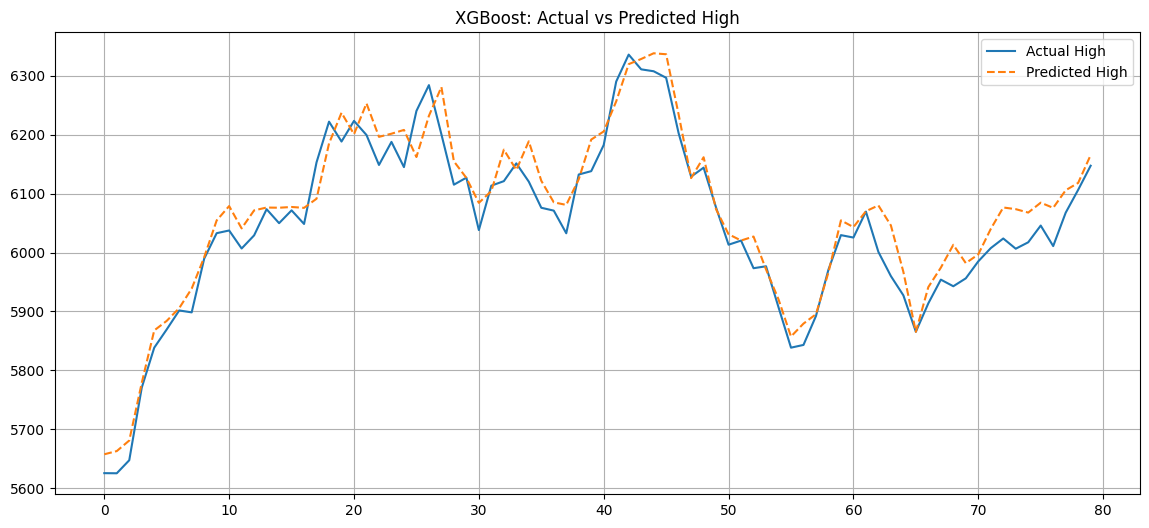

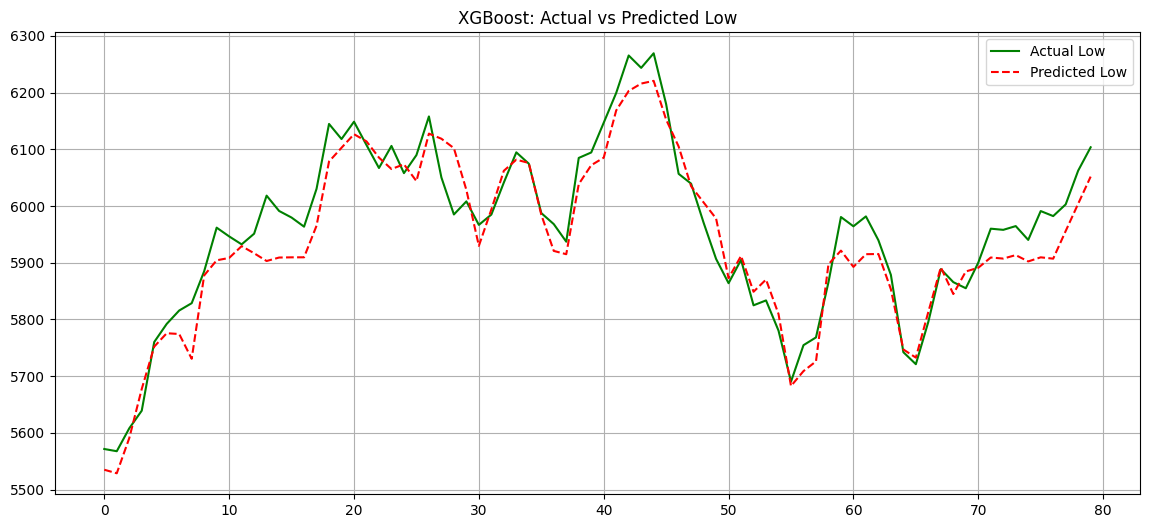

In [22]:
for lag in range(1,6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Drop NaNs
df = df.dropna().reset_index(drop=True)

# Features & target
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-test split (no shuffle)
split_idx = int(len(df)*0.9)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------ TRAIN XGBOOST ------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

# Predict
pred_high = xgb_high.predict(X_test_scaled)
pred_low = xgb_low.predict(X_test_scaled)

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_test, pred_high, "High (XGBoost)")
metrics(y_low_test, pred_low, "Low (XGBoost)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_test.values, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("XGBoost: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_test.values, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("XGBoost: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [24]:
from tensorflow.keras.layers import LSTM, Dense, Dropout

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.3215 - val_loss: 0.0962
Epoch 2/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0507 - val_loss: 0.0171
Epoch 3/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0455 - val_loss: 0.0118
Epoch 4/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0388 - val_loss: 0.0179
Epoch 5/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0372 - val_loss: 0.0128
Epoch 6/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0339 - val_loss: 0.0163
Epoch 7/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0340 - val_loss: 0.0074
Epoch 8/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0322 - val_loss: 0.0066
Epoch 9/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0334 - val_loss: 0.0080
Epoch 10/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0307 - val_loss: 0.0101
Epoch 11/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0319 - val_loss: 0.0068
Epoch 12/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0303 - val_loss: 0.0063


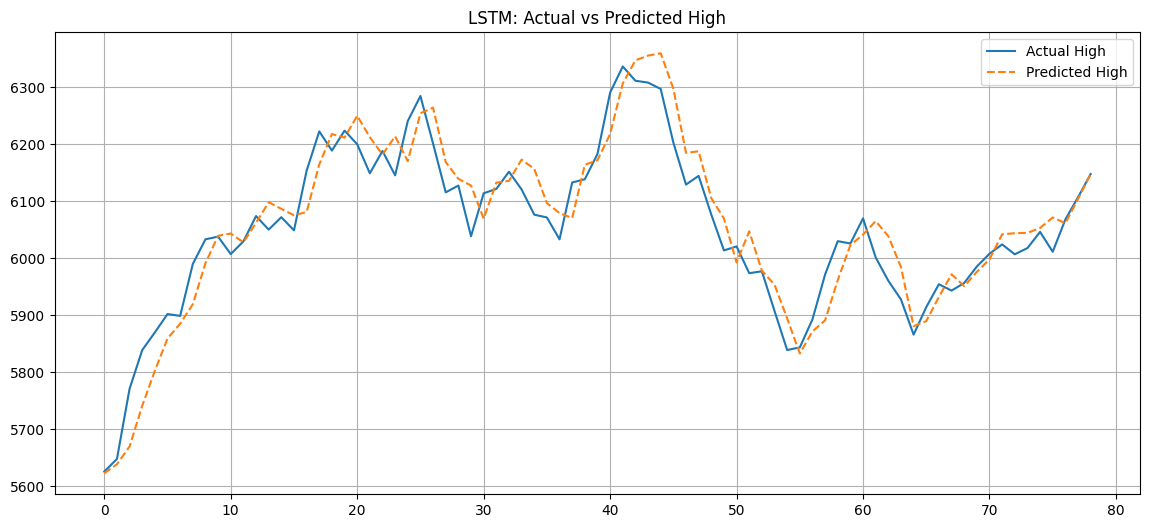

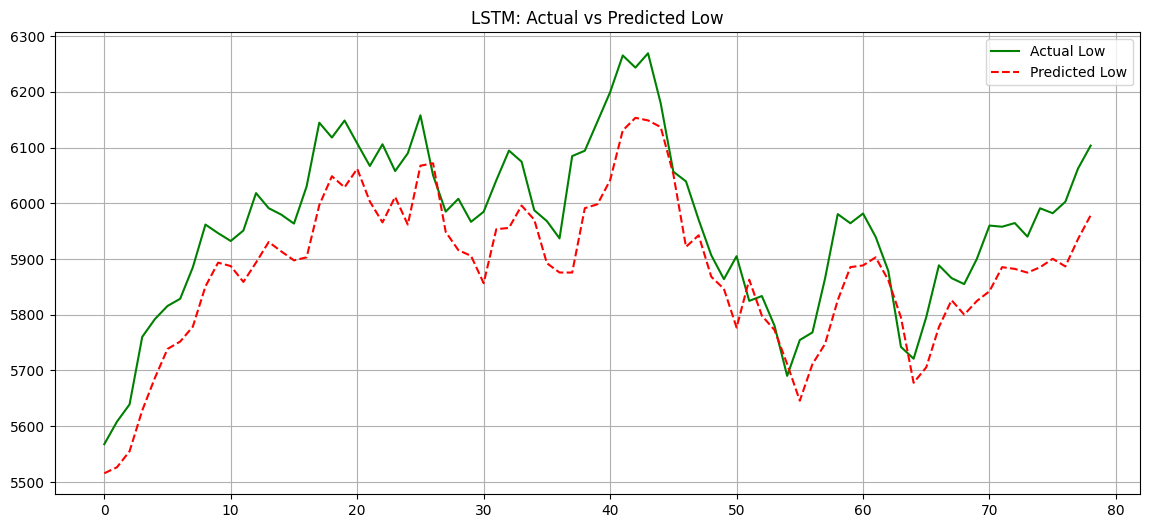

In [25]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2523 - val_loss: 0.0766
Epoch 2/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0577 - val_loss: 0.0157
Epoch 3/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0503 - val_loss: 0.0135
Epoch 4/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0416 - val_loss: 0.0161
Epoch 5/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0424 - val_loss: 0.0098
Epoch 6/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0406 - val_loss: 0.0096
Epoch 7/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0350 - val_loss: 0.0112
Epoch 8/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0371 - val_loss: 0.0209
Epoch 9/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0344 - val_loss: 0.0120
Epoch 10/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0328 - val_loss: 0.0176
Epoch 11/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0340 - val_loss: 0.0137
Epoch 12/25
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0297 - val_loss: 0.0064


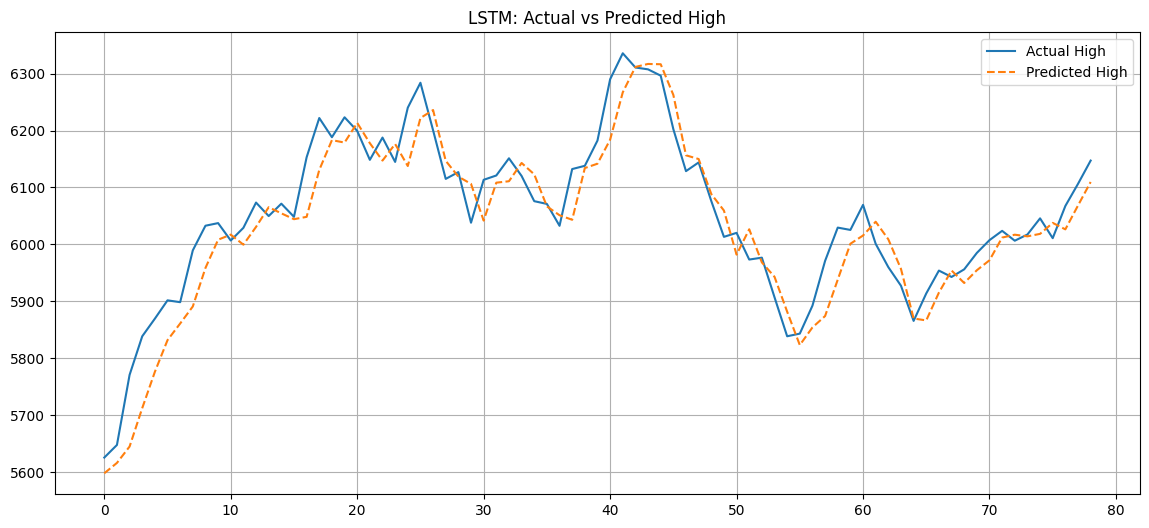

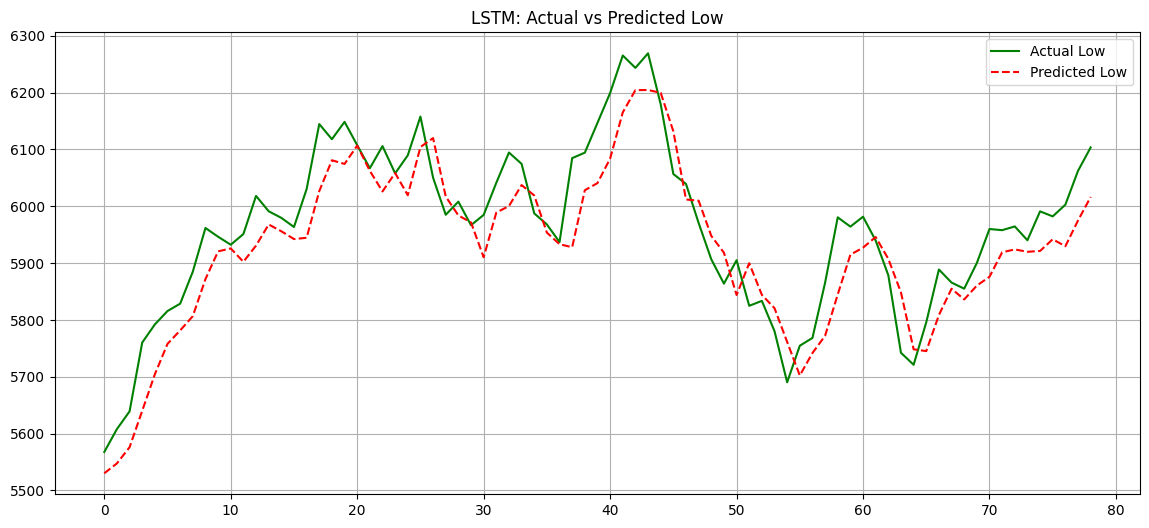

In [26]:
#for sequence length 50
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [29]:
from tcn import TCN

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn (TCN)                       │ (None, 64)             │        87,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         3,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,968 (355.34 KB)

 Trainable params: 90,968 (355.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 7.9704 - val_loss: 0.1357
Epoch 2/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.8036 - val_loss: 0.0916
Epoch 3/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4534 - val_loss: 0.1142
Epoch 4/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3137 - val_loss: 0.0247
Epoch 5/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2880 - val_loss: 0.0824
Epoch 6/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2519 - val_loss: 0.0786
Epoch 7/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1977 - val_loss: 0.0304
Epoch 8/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.2050 - val_loss: 0.0410
Epoch 9/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1800 - val_loss: 0.0549
Epoch 10/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1863 - val_loss: 0.0148
Epoch 11/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1430 - val_loss: 0.0096
Epoch 12/30
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.1511 - val_l

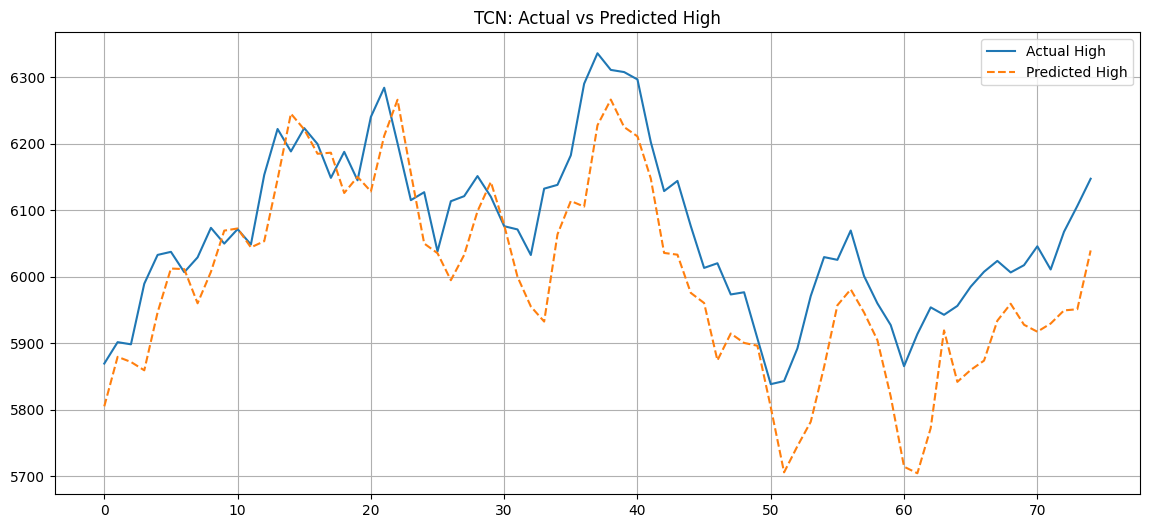

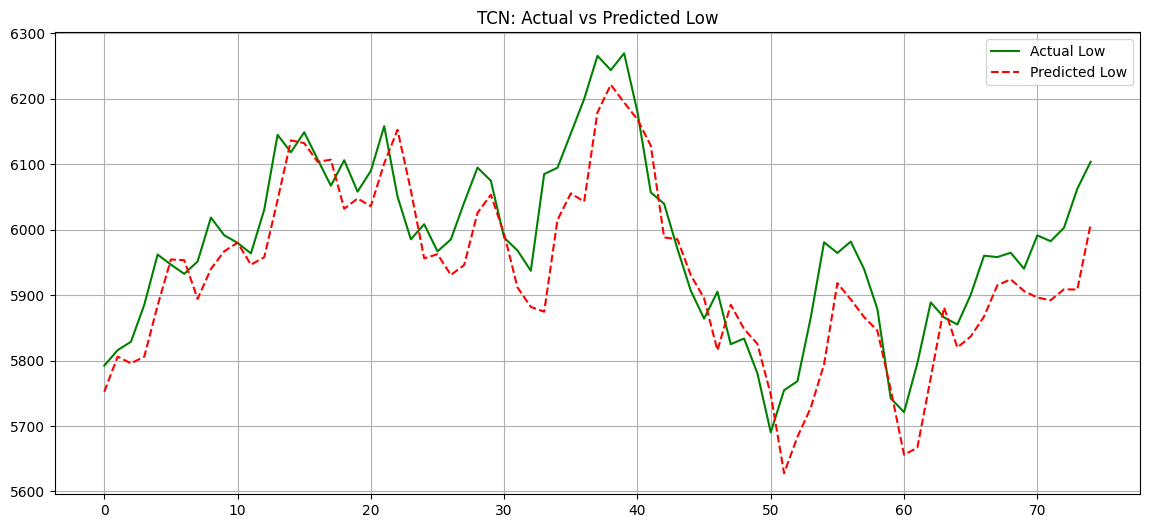

In [30]:





features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y = df[['High','Low']].values

# ------------------ SCALING ------------------
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50  # Hyperparameter: sequence length
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=64,       # Number of convolutional filters
        kernel_size=3,       # Filter/kernel size
        dilations=[1,2,4,8],# Dilation factors for receptive field
        dropout_rate=0.2,    # Dropout for regularization
        return_sequences=False),
    Dense(50, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=30, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

y_high_pred, y_low_pred = y_pred[:,0], y_pred[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, y_high_pred, "High (TCN)")
metrics(y_low_true, y_low_pred, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(y_high_pred, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(y_low_pred, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()
